In [34]:
import ast
import pandas as pd

In [35]:
dfriso=pd.read_csv("outputs/per_protein_diamond_data.tsv",sep="\t",index_col="accession")
hgts=set(dfriso[dfriso.tree_HTG].gene)
dipts=set(dfriso[dfriso.type=='dipt'].gene)
n_hgts=len(hgts)

In [36]:
df=pd.read_csv("ncbi_dataset/data/GCF_014529535.2/genomic.gff",sep="\t",comment="#",header=None)
genes=df[df[2]=='gene']
genes['gene']=[x.split("gene-")[1].split(";")[0] for x in genes[8]]

In [7]:
%%bash
cd ncbi_dataset/data/GCF_014529535.2
wget https://ftp.ncbi.nlm.nih.gov/genomes/all/GCF/014/529/535/GCF_014529535.2_BU_Bcop_v2.1/GCF_014529535.2_BU_Bcop_v2.1_assembly_report.txt

--2026-07-08 18:43:34--  https://ftp.ncbi.nlm.nih.gov/genomes/all/GCF/014/529/535/GCF_014529535.2_BU_Bcop_v2.1/GCF_014529535.2_BU_Bcop_v2.1_assembly_report.txt
Resolving ftp.ncbi.nlm.nih.gov... 130.14.250.31, 130.14.250.13, 2607:f220:41e:250::12, ...
Connecting to ftp.ncbi.nlm.nih.gov|130.14.250.31|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 63287 (62K) [text/plain]
Saving to: ‘GCF_014529535.2_BU_Bcop_v2.1_assembly_report.txt’

     0K .......... .......... .......... .......... .......... 80% 2.18M 0s
    50K .......... .                                          100%  498M=0.02s

2026-07-08 18:43:34 (2.70 MB/s) - ‘GCF_014529535.2_BU_Bcop_v2.1_assembly_report.txt’ saved [63287/63287]



In [37]:
rdf=pd.read_csv("ncbi_dataset/data/GCF_014529535.2/GCF_014529535.2_BU_Bcop_v2.1_assembly_report.txt",sep="\t",comment="#",names="Sequence-Name	Sequence-Role	Assigned-Molecule	Assigned-Molecule-Location/Type	GenBank-Accn	Relationship	RefSeq-Accn	Assembly-Unit	Sequence-Length	UCSC-style-name".split("\t"))
cmap={x:y for x,y in zip(rdf['RefSeq-Accn'],rdf['Assigned-Molecule'])}
lmap={x:y for x,y in zip(rdf['RefSeq-Accn'],rdf['Sequence-Length'])}

In [38]:
genedist=pd.DataFrame(index=['II','III','IV','X','na'], columns=['HGT','Dipteran'])
genedist=genedist.fillna(0)
for index, row in genes.iterrows():
    gene=row[8].split("gene-")[1].split(";")[0]
    loc=row[0]
    if gene in hgts:
        genedist.loc[cmap[loc],"HGT"]+=1
    elif gene in dipts:
        genedist.loc[cmap[loc],"Dipteran"]+=1

/tmp/ipykernel_1786277/2566509321.py:2: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  genedist=genedist.fillna(0)


In [39]:
genedist

,HGT,Dipteran
II,278,2515
III,475,3168
IV,537,3824
X,194,2599
na,33,274


In [40]:
##remove_unplaced scaffolds
genedist=genedist.iloc[0:4,:]
n_hgt=genedist.loc[:,"HGT"].sum()
n_hgt

1484

In [41]:
1517-1484

33

In [42]:
genedistp=genedist.copy()
genedistp["HGT"]=(genedistp.loc[:,"HGT"]/genedistp['HGT'].sum())
genedistp["Dipteran"]=(genedistp.loc[:,"Dipteran"]/genedistp['Dipteran'].sum())

In [43]:
genedistp

,HGT,Dipteran
II,0.187332,0.207748
III,0.320081,0.261688
IV,0.361860,0.315876
X,0.130728,0.214687


In [44]:
genedist['HGT']

II     278
III    475
IV     537
X      194
Name: HGT, dtype: int64

In [23]:
!pip show statsmodels

Name: statsmodels
Version: 0.14.0
Summary: Statistical computations and models for Python
Home-page: https://www.statsmodels.org/
Author: 
Author-email: 
License: BSD License
Location: /n/home11/rkapoor/.conda/envs/rishabh/lib/python3.9/site-packages
Requires: patsy, scipy, numpy, packaging, pandas
Required-by: 


In [45]:
from scipy.stats import chi2_contingency

table = [
    genedist['HGT'],
    genedist['Dipteran']
]

chi2, p, dof, expected = chi2_contingency(table)
print("chi2:", chi2)
print("p:", p)
print("expected:\n", expected)
dof

chi2: 73.54849045701927
p: 7.415903491048464e-16
expected:
 [[ 304.98984547  397.80809419  476.21221486  304.98984547]
 [2488.01015453 3245.19190581 3884.78778514 2488.01015453]]


3

In [46]:

chroms=set(['X','III','II','IV'])
for x in chroms:
    print(x)
    table=[
        [genedist.loc[x,"HGT"],genedist.loc[list(chroms-set([x])),"HGT"].sum()],
        [genedist.loc[x,"Dipteran"],genedist.loc[list(chroms-set([x])),"Dipteran"].sum()]
        
    ]
    chi2, p, dof, expected = chi2_contingency(table)
    print("chi2:", chi2)
    print("p:", p)
    print("expected:\n", expected)

IV
chi2: 12.616582298200967
p: 0.0003823397528011611
expected:
 [[ 476.21221486 1007.78778514]
 [3884.78778514 8221.21221486]]
X
chi2: 56.55805878842998
p: 5.456330919337597e-14
expected:
 [[ 304.98984547 1179.01015453]
 [2488.01015453 9617.98984547]]
II
chi2: 3.250937441870996
p: 0.07138262098556124
expected:
 [[ 304.98984547 1179.01015453]
 [2488.01015453 9617.98984547]]
III
chi2: 22.676267471944534
p: 1.9172124822344356e-06
expected:
 [[ 397.80809419 1086.19190581]
 [3245.19190581 8860.80809419]]


In [47]:
from pycirclize import Circos

In [160]:
!pip show scipy

Name: scipy
Version: 1.8.1
Summary: SciPy: Scientific Library for Python
Home-page: https://www.scipy.org
Author: 
Author-email: 
License: BSD
Location: /n/home11/rkapoor/.conda/envs/rishabh/lib/python3.9/site-packages
Requires: numpy
Required-by: umap-learn, tellurium, statsmodels, scikit-learn, scikit-image, pynndescent, matplotlib-venn, cooltools, cooler


In [86]:
!pip show pycirclize

Name: pyCirclize
Version: 1.7.1
Summary: Circular visualization in Python
Home-page: 
Author: moshi4
Author-email: 
License: 
Location: /n/home11/rkapoor/.conda/envs/rishabh/lib/python3.9/site-packages
Requires: biopython, matplotlib, pandas, numpy
Required-by: 


In [48]:
import matplotlib.pyplot as plt
from matplotlib.font_manager import FontProperties
import matplotlib.font_manager

from pathlib import Path

import matplotlib as mpl

from matplotlib.patches import Patch
from matplotlib.lines import Line2D



fpath = Path(mpl.get_data_path(), "/n/holylabs/LABS/extavour_lab/Users/rkapoor/envs/plot/fonts/arial.ttf")

from matplotlib.font_manager import FontProperties
from matplotlib import font_manager
plt.rcParams['figure.dpi'] = 300
font_path = "/n/holylabs/LABS/extavour_lab/Users/rkapoor/envs/plot/fonts/arial.ttf"
font_manager.fontManager.addfont("/n/holylabs/LABS/extavour_lab/Users/rkapoor/envs/plot/fonts/arial.ttf")
prop = font_manager.FontProperties(fname=font_path)
plt.rcParams['svg.fonttype']='none'

In [49]:
from scipy.stats import pearsonr

In [50]:
genes[0]=[cmap[x] for x in genes[0]]

In [51]:
dfrmerged=pd.read_csv("outputs/SI_inspection_bradysia_6_23_2026.tsv",sep="\t",index_col=0)

In [52]:
##chromosome lengths
lmap2={}
for x in lmap:
    if cmap[x]!='na' and cmap[x]!='MT':
        lmap2[cmap[x]]=lmap[x]
lmap=lmap2

In [53]:
import itertools
maxs=0
##calculate the number of hgt and non-hgt genes in windows of size 100 kb, plot on a circos diagram
##plot connections showing examples of multi-gene hgt families
from pycirclize import Circos
name2color = {"II": "black", "III": "black", "IV": "black",'X':'black'}
sectors=lmap
circos = Circos(sectors, space=5)

for sector in circos.sectors:
    print(sector.name)
    track = sector.add_track((95, 100))
    track.axis(fc=name2color[sector.name])
    track.text(sector.name, color="white", size=12)
    
    x=sector.name
    gffg = genes[genes[0] == x]
    gffg['gene'] = [x.split("gene-")[1].split(";")[0] for x in gffg[8]]
    gffg = gffg[gffg.gene.isin(hgts)]
    n_hgts = []
    step=int(1e5)
    l = list(range(0, lmap[x], int(1e5)))
    xcord=[]
    for i in range(1, len(l)):
        n_hgts.append(gffg[(gffg[3] >= l[i - 1]) & (gffg[3] < l[i])].shape[0])
        xcord.append(l[i])
    print(min(n_hgts),max(n_hgts))
    track1 = sector.add_track((50, 70), r_pad_ratio=0.1)
    track1.axis()
    track1.line(x=xcord,vmin=0,vmax=8, y=n_hgts,color='#ff7f0e')
    y = [0, 4, 8]
    y_labels = list(map(str, y))
    track1.yticks(y, y_labels)
    
    gffg = genes[genes[0] == x]
    gffg['gene'] = [x.split("gene-")[1].split(";")[0] for x in gffg[8]]
    gffg = gffg[gffg.gene.isin(dipts)]
    n_dipt = []
    l = list(range(0, lmap[x], int(1e5)))
    xcord=[]
    for i in range(1, len(l)):
        n_dipt.append(gffg[(gffg[3] >= l[i - 1]) & (gffg[3] < l[i])].shape[0])
        xcord.append(l[i])
    print(min(n_dipt),max(n_dipt))
    print(" ")
    track2 = sector.add_track((75, 95), r_pad_ratio=0.1)
    track2.axis()
    track2.line(x=xcord, y=n_dipt,vmin=0,vmax=21,color=u'#1f77b4')
    y = [0, 10, 20]
    y_labels = list(map(str, y))
    track2.yticks(y, y_labels)
     

II
0 5
0 18
 
III
0 7
0 18
 
X
0 5
0 18
 
IV
0 8
0 16
 


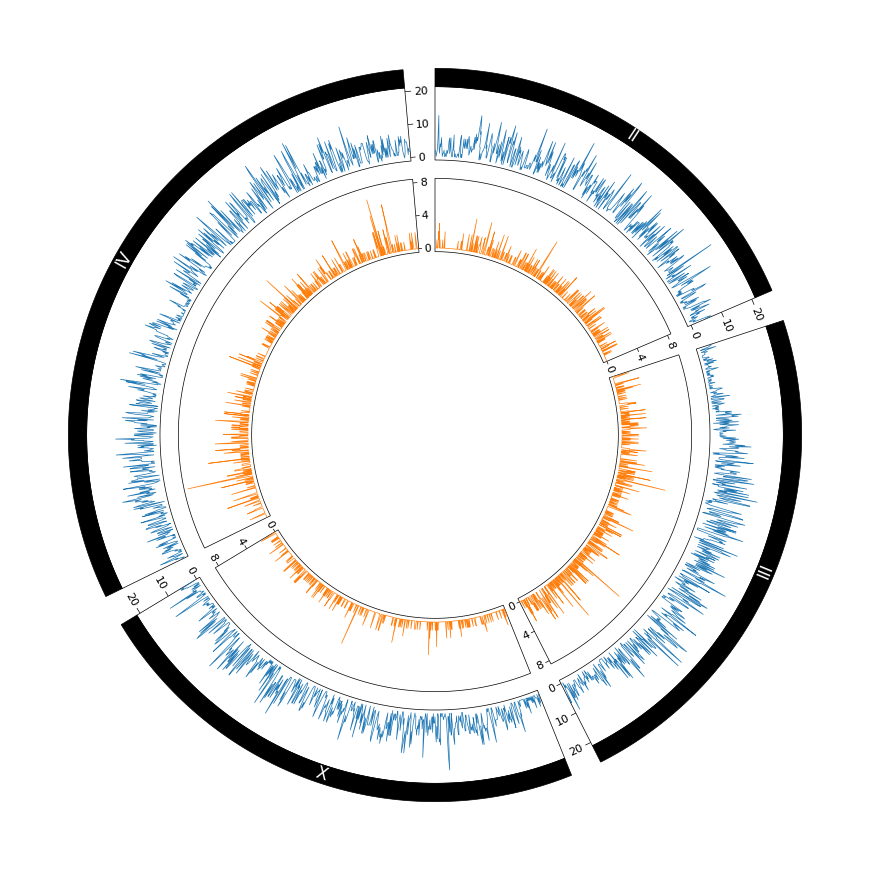

In [54]:
fig = circos.plotfig()
plt.savefig('figures/circos_plot.svg',format='svg')

## Analysis of adjacent HGT clusters

In [55]:
import warnings

# Suppress SettingWithCopyWarning
warnings.filterwarnings('ignore', category=pd.errors.SettingWithCopyWarning)

In [56]:
df=pd.read_csv("ncbi_dataset/data/GCF_014529535.2/genomic.gff",sep="\t",comment="#",header=None)
genes=df[df[2]=='gene']
genes['gene']=[x.split("gene-")[1].split(";")[0] for x in genes[8]]

In [57]:
## create a dataframe storing all pairs of HGT genes that are each others' immediate neighbors
adj_df=pd.DataFrame()
idx=0
n_hgt=0
for x in set(genes[0]):
    gffg=genes[genes[0]==x]
    gffg.loc[list(gffg.index),'gene']=[x.split("gene-")[1].split(";")[0] for x in gffg[8]]

    gffg.index=list(range(gffg.shape[0]))
    gffg['hgt']=[x in set(hgts) for x in gffg.gene]
    l=list(gffg[gffg.hgt].index)
    n_hgt+=len(l)
    for i in range(len(l)-1):
        if l[i+1]==l[i]+1:

            adj_df.loc[idx,['locus_1','locus_2']]=gffg.loc[[l[i],l[i]+1],'gene'].values
            adj_df.loc[idx,['location']]=x
            idx+=1
            

In [58]:
from Bio import SeqIO
from Bio.Seq import Seq

In [59]:
input_file = open(f"ncbi_dataset/data/GCF_014529535.2/longest_isoform.fasta")
fasta = SeqIO.to_dict(SeqIO.parse(input_file, "fasta"))

In [60]:
for index, row in adj_df.iterrows():
    adj_df.loc[index,'prot_1']=dfriso[dfriso.gene==row.locus_1].index.values[0]
    adj_df.loc[index,'prot_2']=dfriso[dfriso.gene==row.locus_2].index.values[0]

In [61]:
for index, row in adj_df.iterrows():
    adj_df.loc[index,'description_prot_1']=fasta[row.prot_1].description
    adj_df.loc[index,'description_prot_2']=fasta[row.prot_2].description
    

In [62]:
s=set()
for index, row in adj_df.iterrows():
    ## add if adjacent pairs are tree-confirmed paralogs
    adj_df.loc[index,'paralogs']=(dfrmerged[dfrmerged.cluster_seqs.str.contains(row.prot_1)].index.values==dfrmerged[dfrmerged.cluster_seqs.str.contains(row.prot_2)].index.values)[0]



In [63]:
## print the number of adjacent pairs that are tree-confirmed paralogs
adj_df[adj_df.paralogs].shape[0]

110

In [64]:
clusters=set()
for index, row in adj_df.iterrows():
    clusters=clusters|set(row[['locus_1','locus_2']])

In [65]:
j=0
cluster_map={}

cluster=list(adj_df.loc[0,['locus_1','locus_2']])
for i in adj_df.index[1:]:
    if adj_df.loc[i,'locus_1']==adj_df.loc[i-1,'locus_2']:
        cluster.append(adj_df.loc[i,'locus_2'])
    else:
        cluster_map[j]=cluster
        cluster=list(adj_df.loc[i,['locus_1','locus_2']])
        j+=1
j+=1
cluster_map[j]=cluster
        
    

In [66]:
len([x for x in cluster_map if len(cluster_map[x])>2])

42

In [67]:
## print the number of clusters
len(cluster_map)

199

In [68]:
len(set(adj_df['locus_1'])|set(adj_df['locus_2']))

462

In [69]:
## add the cluster id number to the row for each pair
for index, row in adj_df.iterrows():
    adj_df.loc[index, 'cluster_number']=[k for k,v in cluster_map.items() if row.locus_1 in v][0]+1

In [70]:
adj_df.to_csv("outputs/genomic_clusters.csv")

## Analyze the proportion of hgt genes immediately neighboring other hgt genes with a simulation

In [46]:
adj_df=pd.read_csv("outputs/genomic_clusters.csv")


In [47]:
dfriso=pd.read_csv("outputs/per_protein_diamond_data.tsv",sep="\t",index_col="accession")
hgts=set(dfriso[dfriso.tree_HTG].gene)
dipts=set(dfriso[dfriso.type=='dipt'].gene)
n_hgts=len(hgts)

In [48]:
df=pd.read_csv("ncbi_dataset/data/GCF_014529535.2/genomic.gff",sep="\t",comment="#",header=None)
genes=df[df[2]=='gene']
genes['gene']=[x.split("gene-")[1].split(";")[0] for x in genes[8]]

In [49]:
##the number of HGTs adjacent to another HGT 
adj_genes=set()
for index, row in adj_df.iterrows():
    adj_genes=adj_genes|set(adj_df.loc[index,['locus_1','locus_2']])

In [50]:
n_adj=len(adj_genes)
n_adj

462

In [51]:
##observed adjacent p
p_adj=n_adj/n_hgts
n_adj,n_hgts,p_adj

(462, 1517, 0.3045484508899143)

In [52]:
##the number of HGTs adjacent to another HGT, excluding tree-defined paralogs
adj_genes=set()
for index, row in adj_df[~adj_df.paralogs].iterrows():
    adj_genes=adj_genes|set(adj_df.loc[index,['locus_1','locus_2']])
n_no_paralogs=len(adj_genes)
p_no_paralogs=n_no_paralogs/n_hgts
p_no_paralogs

0.1891891891891892

In [53]:
import warnings

# Suppress SettingWithCopyWarning
warnings.filterwarnings('ignore', category=pd.errors.SettingWithCopyWarning)

In [54]:
import random
##randomize hgts across genome and calculate p_adj
def sim(idx):
    adj_sim=[]
    tot_sim=0
    ##sample n_hgt fake hgts
    hgt_fake=random.sample(list(genes.gene),n_hgts)
    for x in set(genes[0]):
        gffg=genes[genes[0]==x]
        gffg['gene']=[x.split("gene-")[1].split(";")[0] for x in gffg[8]]
        gffg.index=list(range(gffg.shape[0]))
        
        gffg['hgt']=[x in set(hgt_fake) for x in gffg.gene]
        l=list(gffg[gffg.hgt].index)
        ##determine if adjacent
        for i in range(len(l)-1):
            if l[i+1]==l[i]+1:
                adj_sim.append(tuple(gffg.loc[[l[i],l[i]+1],'gene']))
        adj_sim_genes=set()
        for x in adj_sim:
            adj_sim_genes=adj_sim_genes|set(x)     
    return len(adj_sim_genes)/n_hgts
  

In [55]:
import multiprocessing as mp
num_processes = 90  # Use all available CPU cores
pool = mp.Pool(processes=num_processes)

# Use the pool's map function to apply the get_data function to each element in td
result = pool.map(sim, list(range(10000)))

In [56]:
len([x for x in result if x>p_no_paralogs])/len(result)


0.0028

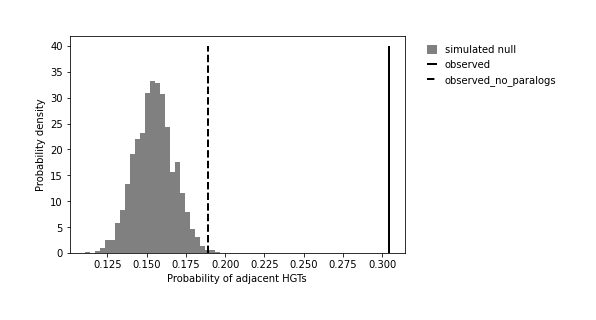

In [57]:
plt.hist(result,bins=30,density=True,color='grey',label='simulated null')
plt.vlines(p_adj,0,40,linewidth=2,label='observed')
plt.vlines(p_no_paralogs,0,40,linewidth=2,label='observed_no_paralogs',linestyle='dashed')
plt.ylabel('Probability density')
plt.xlabel('Probability of adjacent HGTs')
plt.legend(bbox_to_anchor=(1.04, 1))
plt.savefig('figures/p_adjacent_hgt_simulation.svg',format='svg')
plt.show()